# College Football Upset Vulnerability — Notebook 06: Recent Form and Historical Weighting



## 0. Load the saved Stage 2–5 files and inspect the split plan



In [ ]:
from pathlib import Path
from collections import deque
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from google.colab import drive

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/CFB_Upset_Project')
PROCESSED = PROJECT_DIR / 'data' / 'processed'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'validation'

paths = {
    'team_games': PROCESSED / 'team_games.csv',
    'eligibility': PROCESSED / 'game_eligibility_and_splits.csv',
    'matchups_05': PROCESSED / 'matchup_features_opponent_strength.csv',
    'manifest_05': PROCESSED / 'opponent_strength_feature_manifest.json',
    'split_manifest': PROCESSED / 'split_manifest.json',
}
for name, path in paths.items():
    if not path.is_file():
        raise FileNotFoundError(f'Missing {name}: {path}. Run Notebook 05 export first.')

tg_source = pd.read_csv(paths['team_games'], parse_dates=['date'], low_memory=False)
eligibility = pd.read_csv(paths['eligibility'], low_memory=False)
matchups = pd.read_csv(paths['matchups_05'], parse_dates=['date'], low_memory=False)
manifest_05 = json.loads(paths['manifest_05'].read_text(encoding='utf-8'))
split_manifest = json.loads(paths['split_manifest'].read_text(encoding='utf-8'))
folds = split_manifest['validation_folds']
TEST_SEASONS = set(map(int, split_manifest['test_seasons']))
BASELINE_45 = list(manifest_05['candidate_feature_groups']['plus_fbs_and_sos'])

assert TEST_SEASONS == {2024, 2025}, 'Check reserved final-test years'
assert [int(f['validation_season']) for f in folds] == [2019,2020,2021,2022,2023]
assert len(BASELINE_45) == 45 and len(BASELINE_45) == len(set(BASELINE_45))
assert tg_source.groupby('game_id').size().eq(2).all()
assert len(matchups) == len(eligibility) == len(tg_source)//2
assert matchups['game_id'].is_unique and eligibility['game_id'].is_unique

print('Team-game records:', f'{len(tg_source):,}')
print('Matchups:', f'{len(matchups):,}')
print('Notebook 05 reference feature count:', len(BASELINE_45))
print('Validation folds:', [int(f['validation_season']) for f in folds])
print('Final-test seasons remain reserved:', sorted(TEST_SEASONS))
print('scikit-learn:', sklearn.__version__)

Mounted at /content/drive
Team-game records: 36,600
Matchups: 18,300
Notebook 05 reference feature count: 45
Validation folds: [2019, 2020, 2021, 2022, 2023]
Final-test seasons remain reserved: [2024, 2025]
scikit-learn: 1.6.1


## 1. Attach season-specific subdivision labels



In [ ]:
elig_cols = ['game_id','season','home','away','home_subdivision','away_subdivision']
assert set(elig_cols).issubset(eligibility.columns)
tg = tg_source.merge(
    eligibility[elig_cols], on=['game_id','season'], how='left',
    validate='many_to_one', indicator=True
)
assert tg['_merge'].eq('both').all(), 'Missing subdivision joins'
tg.drop(columns='_merge', inplace=True)

home_flags = tg['designated_home'].astype('string').str.strip().str.lower()
assert home_flags.isin(['true','false','1','0']).all()
tg['designated_home'] = home_flags.isin(['true','1'])
assert (tg.team.to_numpy() == np.where(tg.designated_home,tg.home,tg.away)).all()
assert (tg.opponent.to_numpy() == np.where(tg.designated_home,tg.away,tg.home)).all()

tg['opponent_subdivision'] = np.where(
    tg.designated_home, tg.away_subdivision, tg.home_subdivision
)
tg['opponent_is_fbs'] = tg.opponent_subdivision.eq('fbs')
tg = tg.sort_values(['team','season','date','game_id'],kind='stable').reset_index(drop=True)
assert tg['date'].notna().all()
assert not tg.duplicated(['team','date']).any(), 'Same-date games require special handling'
assert tg.groupby('game_id').size().eq(2).all()

print('Recorded team-games by opponent subdivision:')
display(tg.opponent_subdivision.value_counts(dropna=False).to_frame('team_games'))
print('Records with known FBS opponents:', f'{tg.opponent_is_fbs.mean():.1%}')

Recorded team-games by opponent subdivision:


,team_games
opponent_subdivision,
fbs,34469
fcs,2105
unknown,25
d2,1


Records with known FBS opponents: 94.2%


## 2. Construct four **strictly pregame** recent-form alternatives


In [ ]:
# Run a small state machine inside each team-season. We write features BEFORE observing this row.
HALF_LIVES = [2, 4]
DECAY = {h: 0.5 ** (1.0/h) for h in HALF_LIVES}
new_recent = [
    'recent_fbs_3_count', 'recent_fbs_3_avg_margin', 'recent_fbs_3_win_pct',
    'recent_fbs_5_count', 'recent_fbs_5_avg_margin', 'recent_fbs_5_win_pct',
    'recent_fbs_ewm2_avg_margin', 'recent_fbs_ewm2_win_pct',
    'recent_fbs_ewm4_avg_margin', 'recent_fbs_ewm4_win_pct',
]
store = {name: np.full(len(tg), np.nan) for name in new_recent}

for (team, season), idx in tg.groupby(['team','season'],sort=False).indices.items():
    # Indices follow sorted row order. Each group starts with no current-season history.
    past_margin = deque(maxlen=5)
    past_win = deque(maxlen=5)
    weighted_margin = {h: 0.0 for h in HALF_LIVES}
    weighted_win = {h: 0.0 for h in HALF_LIVES}
    weights = {h: 0.0 for h in HALF_LIVES}

    for pos in idx:
        for k in [3, 5]:
            vals_m = list(past_margin)[-k:]
            vals_w = list(past_win)[-k:]
            store[f'recent_fbs_{k}_count'][pos] = len(vals_m)
            if vals_m:
                store[f'recent_fbs_{k}_avg_margin'][pos] = np.mean(vals_m)
                store[f'recent_fbs_{k}_win_pct'][pos] = np.mean(vals_w)

        for h in HALF_LIVES:
            if weights[h] > 0:
                store[f'recent_fbs_ewm{h}_avg_margin'][pos] = weighted_margin[h]/weights[h]
                store[f'recent_fbs_ewm{h}_win_pct'][pos] = weighted_win[h]/weights[h]

        # Update after taking the snapshot; never insert current-game output as input.
        if bool(tg.at[pos,'opponent_is_fbs']):
            margin = float(tg.at[pos,'margin'])
            win = float(tg.at[pos,'win'])
            assert np.isfinite(margin) and win in (0., 1.)
            past_margin.append(margin)
            past_win.append(win)
            for h in HALF_LIVES:
                weighted_margin[h] = DECAY[h]*weighted_margin[h] + margin
                weighted_win[h] = DECAY[h]*weighted_win[h] + win
                weights[h] = DECAY[h]*weights[h] + 1.0

for name, values in store.items():
    tg[name] = values

assert tg.loc[tg.season_prior_games.eq(0),
    [x for x in new_recent if 'avg_margin' in x or 'win_pct' in x]].isna().all().all()
assert (tg['recent_fbs_3_count'] <= 3).all()
assert (tg['recent_fbs_5_count'] <= 5).all()
assert (tg.recent_fbs_3_count <= tg.recent_fbs_5_count).all()

print('Recent-form feature columns:', len(new_recent))
display(tg.loc[(tg.team=='Kansas State') & (tg.season==2025),
    ['date','opponent','opponent_subdivision','margin','win',
     'recent_fbs_3_count','recent_fbs_3_avg_margin','recent_fbs_5_avg_margin',
     'recent_fbs_ewm2_avg_margin']].head(10))

Recent-form feature columns: 10


,date,opponent,opponent_subdivision,margin,win,recent_fbs_3_count,recent_fbs_3_avg_margin,recent_fbs_5_avg_margin,recent_fbs_ewm2_avg_margin
13001,2025-08-23,Iowa State,fbs,-3,0,0.0,NaN,NaN,NaN
13002,2025-08-30,North Dakota,fcs,3,1,1.0,-3.000000,-3.0,-3.000000
13003,2025-09-06,Army,fbs,-3,0,1.0,-3.000000,-3.0,-3.000000
13004,2025-09-12,Arizona,fbs,-6,0,2.0,-3.000000,-3.0,-3.000000
13005,2025-09-27,UCF,fbs,14,1,3.0,-4.000000,-4.0,-4.359246
13006,2025-10-04,Baylor,fbs,-1,0,3.0,1.666667,0.5,2.810486
13007,2025-10-11,TCU,fbs,13,1,3.0,2.333333,0.2,1.454760
13008,2025-10-25,Kansas,fbs,25,1,3.0,8.666667,3.4,5.319357
13009,2025-11-01,Texas Tech,fbs,-23,0,3.0,12.333333,9.0,11.642583
13010,2025-11-15,Oklahoma State,fbs,8,1,3.0,5.000000,5.6,0.819567


## 3. Independently audit the recent-form snapshots



In [ ]:
def weighted_prior_average(values, half_life):
    if not len(values):
        return np.nan
    discount = 0.5 ** (1.0/half_life)
    weights = discount ** np.arange(len(values)-1,-1,-1)
    return float(np.average(values,weights=weights))

sample = tg.sample(n=min(100,len(tg)),random_state=42)
for row in sample.itertuples(index=False):
    prior = tg.loc[(tg.team.eq(row.team)) & (tg.season.eq(row.season)) &
                   (tg.date.lt(row.date)) & (tg.opponent_is_fbs)]
    for k in [3,5]:
        short = prior.tail(k)
        assert int(getattr(row,f'recent_fbs_{k}_count')) == len(short)
        assert np.isclose(getattr(row,f'recent_fbs_{k}_avg_margin'),
                          short.margin.mean(),equal_nan=True)
        assert np.isclose(getattr(row,f'recent_fbs_{k}_win_pct'),
                          short.win.mean(),equal_nan=True)
    for h in HALF_LIVES:
        expected_m = weighted_prior_average(prior.margin.to_numpy(),h)
        expected_w = weighted_prior_average(prior.win.to_numpy(),h)
        assert np.isclose(getattr(row,f'recent_fbs_ewm{h}_avg_margin'),expected_m,equal_nan=True)
        assert np.isclose(getattr(row,f'recent_fbs_ewm{h}_win_pct'),expected_w,equal_nan=True)

first = tg.loc[tg.season_prior_games.eq(0)]
assert first.recent_fbs_3_count.eq(0).all() and first.recent_fbs_5_count.eq(0).all()
assert first[[c for c in new_recent if 'avg_margin' in c or 'win_pct' in c]].isna().all().all()
print(f'Recent-feature checks passed: {len(sample)} independent snapshots; {len(first):,} first-of-season rows.')

Recent-feature checks passed: 100 independent snapshots; 4,444 first-of-season rows.


## 4. Construct prior-season features (1 year vs weighted 3 years)



In [ ]:
# Aggregate completed seasons, retaining only games against verified FBS opponents.
fbs_history = tg.loc[tg.opponent_is_fbs, ['team','season','margin','win']].copy()
by_year = fbs_history.groupby(['team','season'],as_index=False).agg(
    fbs_games=('win','size'),
    fbs_wins=('win','sum'),
    fbs_margin_sum=('margin','sum')
)
assert by_year['fbs_games'].ge(1).all()

season_keys = tg[['team','season']].drop_duplicates().copy()
for lag in [1,2,3]:
    prior_data = by_year.rename(columns={
        'season':'prior_season',
        'fbs_games':f'_lag{lag}_games',
        'fbs_wins':f'_lag{lag}_wins',
        'fbs_margin_sum':f'_lag{lag}_margin_sum',
    }).copy()
    season_keys[f'_lag{lag}_season'] = season_keys.season - lag
    season_keys = season_keys.merge(
        prior_data, left_on=['team',f'_lag{lag}_season'], right_on=['team','prior_season'],
        how='left', validate='many_to_one'
    ).drop(columns='prior_season')
    for key in [f'_lag{lag}_games',f'_lag{lag}_wins',f'_lag{lag}_margin_sum']:
        season_keys[key] = season_keys[key].fillna(0)

season_keys['prev1_fbs_games'] = season_keys['_lag1_games']
season_keys['prev1_fbs_win_pct'] = (
    season_keys['_lag1_wins'] / season_keys['_lag1_games'].replace(0,np.nan)
)
season_keys['prev1_fbs_avg_margin'] = (
    season_keys['_lag1_margin_sum'] / season_keys['_lag1_games'].replace(0,np.nan)
)

# Exponentially discount entire previous seasons, not individual games.
DECAY_BY_YEAR = 0.5
weights = [DECAY_BY_YEAR**(lag-1) for lag in [1,2,3]]
weighted_games = sum(w*season_keys[f'_lag{lag}_games'] for lag,w in zip([1,2,3],weights))
weighted_wins = sum(w*season_keys[f'_lag{lag}_wins'] for lag,w in zip([1,2,3],weights))
weighted_margin = sum(w*season_keys[f'_lag{lag}_margin_sum'] for lag,w in zip([1,2,3],weights))
season_keys['prev3_fbs_observed_games'] = sum(season_keys[f'_lag{lag}_games'] for lag in [1,2,3])
season_keys['prev3_fbs_observed_seasons'] = sum(season_keys[f'_lag{lag}_games'].gt(0).astype(int) for lag in [1,2,3])
season_keys['prev3_fbs_weighted_win_pct'] = weighted_wins / weighted_games.replace(0,np.nan)
season_keys['prev3_fbs_weighted_avg_margin'] = weighted_margin / weighted_games.replace(0,np.nan)

HIST_COLS = ['prev1_fbs_games','prev1_fbs_win_pct','prev1_fbs_avg_margin',
             'prev3_fbs_observed_games','prev3_fbs_observed_seasons',
             'prev3_fbs_weighted_win_pct','prev3_fbs_weighted_avg_margin']
tg = tg.merge(season_keys[['team','season']+HIST_COLS],on=['team','season'],
              how='left',validate='many_to_one')
assert tg[HIST_COLS].notna().any(axis=1).all(), 'At least counts should be present'
assert tg.loc[tg.season.eq(2004),'prev1_fbs_games'].eq(0).all()
assert tg.loc[tg.season.eq(2004),'prev3_fbs_observed_games'].eq(0).all()
assert tg.loc[tg.prev1_fbs_games.eq(0),['prev1_fbs_win_pct','prev1_fbs_avg_margin']].isna().all().all()

print('Prior-season columns:',len(HIST_COLS))
display(tg.loc[(tg.team=='Kansas State') & (tg.season.isin([2023,2024,2025])),
    ['season','date','opponent','prev1_fbs_games','prev1_fbs_avg_margin',
     'prev3_fbs_observed_games','prev3_fbs_weighted_avg_margin']].groupby('season').head(1))

Prior-season columns: 7


,season,date,opponent,prev1_fbs_games,prev1_fbs_avg_margin,prev3_fbs_observed_games,prev3_fbs_weighted_avg_margin
12975,2023,2023-09-02,SE Missouri State,13.0,8.615385,35.0,6.348837
12988,2024,2024-08-31,Tennessee-Martin,12.0,13.666667,37.0,11.127907
13001,2025,2025-08-23,Iowa State,12.0,5.166667,37.0,8.094118


## 5. Audit prior-season features and eligibility



In [ ]:
sample_keys = season_keys[['team','season']].sample(n=min(80,len(season_keys)),random_state=24)
for row in sample_keys.itertuples(index=False):
    past1 = fbs_history.loc[(fbs_history.team==row.team) & (fbs_history.season==row.season-1)]
    got = tg.loc[(tg.team==row.team)&(tg.season==row.season)].iloc[0]
    assert int(got.prev1_fbs_games) == len(past1)
    assert np.isclose(got.prev1_fbs_avg_margin,past1.margin.mean(),equal_nan=True)
    assert np.isclose(got.prev1_fbs_win_pct,past1.win.mean(),equal_nan=True)
    prior = fbs_history.loc[(fbs_history.team==row.team) &
                            (fbs_history.season.between(row.season-3,row.season-1))].copy()
    expected_n = len(prior)
    assert int(got.prev3_fbs_observed_games) == expected_n
    if expected_n:
        w = DECAY_BY_YEAR**(row.season - prior.season.to_numpy() - 1)
        assert np.isclose(got.prev3_fbs_weighted_avg_margin,np.average(prior.margin,weights=w))
        assert np.isclose(got.prev3_fbs_weighted_win_pct,np.average(prior.win,weights=w))
    else:
        assert pd.isna(got.prev3_fbs_weighted_avg_margin)

variation = tg.groupby(['team','season'])[HIST_COLS].nunique(dropna=False)
assert variation.le(1).all().all(), 'History shifted inside season: potential leakage'
assert (tg.prev3_fbs_observed_games >= tg.prev1_fbs_games).all()
print(f'Prior-season checks passed: {len(sample_keys)} independently verified team-seasons.')
print('No current-season or future-season results enter historical priors.')

Prior-season checks passed: 80 independently verified team-seasons.
No current-season or future-season results enter historical priors.


## 6. Assemble matchup features and pre-register comparisons



In [ ]:
RECENT_3 = ['recent_fbs_3_count','recent_fbs_3_avg_margin','recent_fbs_3_win_pct']
RECENT_5 = ['recent_fbs_5_count','recent_fbs_5_avg_margin','recent_fbs_5_win_pct']
EWM2 = ['recent_fbs_ewm2_avg_margin','recent_fbs_ewm2_win_pct']
EWM4 = ['recent_fbs_ewm4_avg_margin','recent_fbs_ewm4_win_pct']
PREV1 = ['prev1_fbs_games','prev1_fbs_win_pct','prev1_fbs_avg_margin']
PREV3 = ['prev3_fbs_observed_games','prev3_fbs_observed_seasons',
         'prev3_fbs_weighted_win_pct','prev3_fbs_weighted_avg_margin']
ALL_SIDE_NEW = list(dict.fromkeys(RECENT_3+RECENT_5+EWM2+EWM4+PREV1+PREV3))

def make_side(side):
    home_side = side=='home'
    res = tg.loc[tg.designated_home.eq(home_side),['game_id','team',*ALL_SIDE_NEW]].copy()
    return res.rename(columns={'team':side,**{c:f'{side}_{c}' for c in ALL_SIDE_NEW}})

more = matchups.merge(make_side('home'),on=['game_id','home'],how='left',validate='one_to_one')
more = more.merge(make_side('away'),on=['game_id','away'],how='left',validate='one_to_one')
assert len(more)==len(matchups) and more.game_id.is_unique
for name in ALL_SIDE_NEW:
    if name.endswith(('win_pct','avg_margin')):
        more[f'diff_{name}'] = more[f'home_{name}']-more[f'away_{name}']

def add_cols(group):
    added = [f'{side}_{c}' for side in ['home','away'] for c in group]
    added += [f'diff_{c}' for c in group if c.endswith(('win_pct','avg_margin'))]
    return added

FEATURE_SETS = {
    'baseline_45': BASELINE_45,
    'recent_last3': BASELINE_45 + add_cols(RECENT_3),
    'recent_last5': BASELINE_45 + add_cols(RECENT_5),
    'recent_ewm2': BASELINE_45 + add_cols(EWM2),
    'recent_ewm4': BASELINE_45 + add_cols(EWM4),
    'prior_1season': BASELINE_45 + add_cols(PREV1),
    'prior_3seasons_decay': BASELINE_45 + add_cols(PREV3),
    'recent_ewm2_plus_prior1': BASELINE_45 + add_cols(EWM2 + PREV1),
}
BANNED = {'home_win','home_margin','score_home','score_away','win','margin',
          'game_id','season','date','team','opponent','home','away','partition'}
for name, cols in FEATURE_SETS.items():
    assert len(cols)==len(set(cols)), f'Duplicate features: {name}'
    assert set(cols).issubset(more.columns), f'Missing feature columns: {name}'
    assert set(cols).isdisjoint(BANNED), f'Possible leakage: {name}'

print('Candidate groups and feature counts:')
for name, cols in FEATURE_SETS.items(): print(f' - {name}: {len(cols)}')
print('New-feature missingness in validation-era games (descriptive only):')
validation_names = more.loc[more.season.between(2019,2023)]
display(validation_names[[f'home_{c}' for c in ALL_SIDE_NEW]].isna().mean()
        .mul(100).sort_values(ascending=False).head(10).rename('missing_pct').to_frame().round(1))

Candidate groups and feature counts:
 - baseline_45: 45
 - recent_last3: 53
 - recent_last5: 53
 - recent_ewm2: 51
 - recent_ewm4: 51
 - prior_1season: 53
 - prior_3seasons_decay: 55
 - recent_ewm2_plus_prior1: 59
New-feature missingness in validation-era games (descriptive only):


,missing_pct
home_recent_fbs_3_avg_margin,11.4
home_recent_fbs_ewm2_win_pct,11.4
home_recent_fbs_3_win_pct,11.4
home_recent_fbs_5_avg_margin,11.4
home_recent_fbs_5_win_pct,11.4
home_recent_fbs_ewm4_avg_margin,11.4
home_recent_fbs_ewm2_avg_margin,11.4
home_recent_fbs_ewm4_win_pct,11.4
home_prev1_fbs_avg_margin,0.6
home_prev1_fbs_win_pct,0.6


## 7. Compare all candidates on identical expanding-window validation folds



In [ ]:
join_keys=['game_id','season','home','away']
assert eligibility.game_id.is_unique
assert more.game_id.is_unique
modeling = more.merge(eligibility[join_keys+['primary_fbs_fbs']],
                      on=join_keys,how='left',validate='one_to_one',indicator=True)
assert modeling['_merge'].eq('both').all()
modeling.drop(columns='_merge',inplace=True)
is_fbs_fbs = modeling.primary_fbs_fbs.astype('string').str.strip().str.lower().isin(['true','1'])
modeling = modeling.loc[is_fbs_fbs & ~modeling.season.isin(TEST_SEASONS)].copy()
assert modeling.season.max()==2023 and modeling.season.min()==2004
assert not modeling.season.isin(TEST_SEASONS).any()
assert len(modeling)==int(eligibility.loc[eligibility.season.le(2023),'primary_fbs_fbs']
                          .astype('string').str.lower().isin(['true','1']).sum())

all_features = list(dict.fromkeys(c for cols in FEATURE_SETS.values() for c in cols))
for col in all_features:
    if col == 'neutral':
        modeling[col] = modeling[col].astype('string').str.lower().map(
            {'true':1.0,'false':0.0,'1':1.0,'0':0.0})
        assert modeling[col].notna().all()
    else:
        missing_before = int(modeling[col].isna().sum())
        modeling[col] = pd.to_numeric(modeling[col], errors='coerce')
        assert modeling[col].isna().sum() == missing_before, f'Unexpected nonnumeric data: {col}'

def model_pipeline():
    return Pipeline([
        ('imputer',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),
        ('scaler',StandardScaler()),
        ('classifier',LogisticRegression(solver='lbfgs',C=1.0,max_iter=2000,random_state=42))
    ])

def evaluate(y,p):
    y=np.asarray(y,dtype=int)
    p=np.asarray(p,dtype=float)
    assert np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    return {
        'n_games':len(y),
        'accuracy':accuracy_score(y,p>=0.5),
        'brier':brier_score_loss(y,p),
        'log_loss':log_loss(y,p,labels=[0,1]),
        'roc_auc':roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,
    }

fold_rows=[]
oof_rows=[]
for fold in folds:
    first,last=map(int,fold['train_seasons'])
    year=int(fold['validation_season'])
    assert first==2004 and last==year-1
    train=modeling.loc[modeling.season.between(first,last)]
    valid=modeling.loc[modeling.season.eq(year)]
    assert train.season.max()<valid.season.min()
    assert not set(train.game_id).intersection(valid.game_id)
    for name,cols in FEATURE_SETS.items():
        pipe=model_pipeline()
        pipe.fit(train[cols],train.home_win.astype(int))
        p=pipe.predict_proba(valid[cols])[:,list(pipe.named_steps['classifier'].classes_).index(1)]
        fold_rows.append({'fold':fold['fold'],'validation_season':year,
                          'model':name,'n_train':len(train),**evaluate(valid.home_win,p)})
        tmp=valid[['game_id','season','date','home','away','home_win']].copy()
        tmp['model']=name
        tmp['predicted_p_home_win']=p
        oof_rows.append(tmp)
    print(f'Validated {year}: {len(train):,} train / {len(valid):,} validation games')

fold_scores = pd.DataFrame(fold_rows)
oof = pd.concat(oof_rows,ignore_index=True)
assert oof.groupby(['model','game_id']).size().eq(1).all()
assert not oof.season.isin(TEST_SEASONS).any()
print('Per-season Brier score:')
display(fold_scores.pivot(index='validation_season',columns='model',values='brier').round(5))

Validated 2019: 10,917 train / 774 validation games
Validated 2020: 11,691 train / 534 validation games
Validated 2021: 12,225 train / 770 validation games
Validated 2022: 12,995 train / 776 validation games
Validated 2023: 13,771 train / 792 validation games
Per-season Brier score:


model,baseline_45,prior_1season,prior_3seasons_decay,recent_ewm2,recent_ewm2_plus_prior1,recent_ewm4,recent_last3,recent_last5
validation_season,,,,,,,,
2019,0.18745,0.18335,0.17994,0.18820,0.18364,0.18816,0.18688,0.18878
2020,0.20415,0.19204,0.19313,0.20374,0.19158,0.20377,0.20551,0.20479
2021,0.19834,0.19556,0.19071,0.19828,0.19531,0.19813,0.19848,0.19810
2022,0.20309,0.20085,0.19985,0.20235,0.19998,0.20236,0.20243,0.20246
2023,0.19194,0.18595,0.18510,0.19176,0.18560,0.19167,0.19204,0.19123


## 8. Compare pooled results, inspect per-season deltas, and visualize



Pooled validation results (lower Brier/log loss is better):


,model,n_games,accuracy,brier,log_loss,roc_auc,delta_brier_vs_45
0,prior_3seasons_decay,3646,0.71476,0.18950,0.55976,0.77428,-0.00700
1,recent_ewm2_plus_prior1,3646,0.71009,0.19117,0.56302,0.77030,-0.00533
2,prior_1season,3646,0.70954,0.19149,0.56391,0.76957,-0.00501
3,recent_ewm4,3646,0.70269,0.19634,0.57562,0.75483,-0.00016
4,recent_ewm2,3646,0.70296,0.19639,0.57575,0.75449,-0.00011
5,recent_last3,3646,0.70159,0.19649,0.57604,0.75410,-0.00001
6,baseline_45,3646,0.70214,0.19650,0.57609,0.75412,0.00000
7,recent_last5,3646,0.70077,0.19654,0.57620,0.75422,0.00004


Notebook 05 baseline reproducibility difference: 0.000010282
NOTE: Baseline reproduction is not exact. Brier difference: 0.000010282. Prediction differences were checked separately.
Brier change from baseline_45 by season (negative = improvement):


model,baseline_45,prior_1season,prior_3seasons_decay,recent_ewm2,recent_ewm2_plus_prior1,recent_ewm4,recent_last3,recent_last5
validation_season,,,,,,,,
2019,0.0,-0.00411,-0.00751,0.00075,-0.00382,0.00070,-0.00058,0.00133
2020,0.0,-0.01211,-0.01102,-0.00041,-0.01257,-0.00038,0.00136,0.00064
2021,0.0,-0.00278,-0.00763,-0.00006,-0.00302,-0.00021,0.00014,-0.00024
2022,0.0,-0.00223,-0.00324,-0.00073,-0.00310,-0.00073,-0.00066,-0.00063
2023,0.0,-0.00599,-0.00685,-0.00018,-0.00634,-0.00027,0.00010,-0.00071


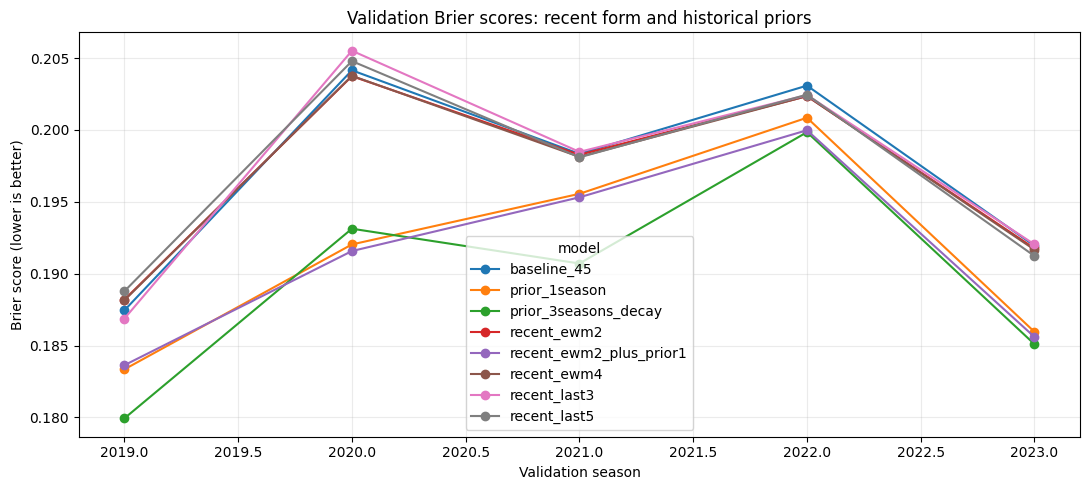

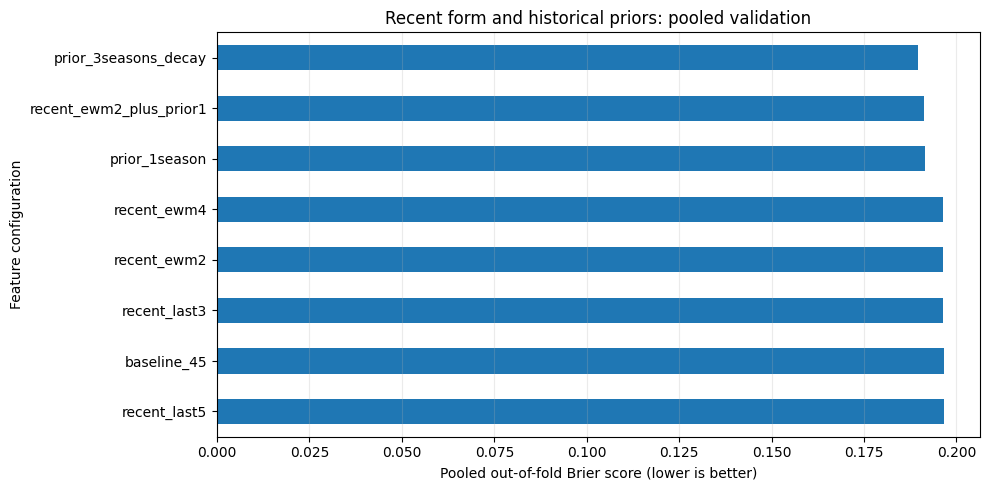

In [ ]:
pooled_rows=[]
for name, subset in oof.groupby('model'):
    pooled_rows.append({'model':name,**evaluate(subset.home_win,subset.predicted_p_home_win)})
pooled = pd.DataFrame(pooled_rows).sort_values('brier').reset_index(drop=True)
base = float(pooled.loc[pooled.model.eq('baseline_45'),'brier'].iloc[0])
pooled['delta_brier_vs_45'] = pooled['brier'] - base
print('Pooled validation results (lower Brier/log loss is better):')
display(pooled.round(5))

# Cross-check exactly against the exported Notebook 05 baseline where available.
previous_path = OUTPUT_DIR / 'opponent_strength_pooled_scores.csv'
if previous_path.is_file():
    prev = pd.read_csv(previous_path)
    expected = prev.loc[prev.model.eq('plus_fbs_and_sos'),'brier']
    if len(expected)==1:
        discrepancy = abs(base-float(expected.iloc[0]))
        print(f'Notebook 05 baseline reproducibility difference: {discrepancy:.9f}')
        if discrepancy >= 1e-7:
          print(
           "NOTE: Baseline reproduction is not exact. "
            f"Brier difference: {discrepancy:.9f}. "
            "Prediction differences were checked separately."
          )

# Guard against substantial baseline changes
assert discrepancy < 1e-4, (
    "Baseline difference exceeds the diagnostic tolerance."
)
pivot = fold_scores.pivot(index='validation_season',columns='model',values='brier')
season_delta = pivot.subtract(pivot['baseline_45'],axis=0)
print('Brier change from baseline_45 by season (negative = improvement):')
display(season_delta.round(5))

ax = pivot.plot(figsize=(11,5),marker='o')
ax.set(xlabel='Validation season',ylabel='Brier score (lower is better)',
       title='Validation Brier scores: recent form and historical priors')
ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

ax2 = pooled.sort_values('brier',ascending=False).plot.barh(
    x='model',y='brier',legend=False,figsize=(10,5))
ax2.set(xlabel='Pooled out-of-fold Brier score (lower is better)',
        ylabel='Feature configuration',title='Recent form and historical priors: pooled validation')
ax2.grid(axis='x',alpha=.25)
plt.tight_layout()
plt.show()

## 9. Save artifacts to Google Drive



In [ ]:
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
PROCESSED.mkdir(parents=True,exist_ok=True)
files={
    'enhanced_matchups':PROCESSED/'matchup_features_recent_history.csv',
    'feature_manifest':PROCESSED/'recent_history_feature_manifest.json',
    'fold_scores':OUTPUT_DIR/'recent_history_fold_scores.csv',
    'pooled_scores':OUTPUT_DIR/'recent_history_pooled_scores.csv',
    'oof_predictions':OUTPUT_DIR/'recent_history_oof_predictions_2019_2023.csv',
    'season_deltas':OUTPUT_DIR/'recent_history_brier_deltas_by_season.csv',
}
more.to_csv(files['enhanced_matchups'],index=False)
config={
    'purpose':'Compare rolling FBS game form, exponentially weighted form, and completed prior-season history',
    'baseline_notebook':'05_Opponent_Strength_Experiments.ipynb',
    'feature_sets':FEATURE_SETS,
    'recent_half_lives_fbs_games':HALF_LIVES,
    'prior_3season_yearly_discount':DECAY_BY_YEAR,
    'source_opponent_division':'historical season-specific eligibility',
    'primary_metric':'pooled_out_of_fold_brier',
    'validation_folds':folds,
    'reserved_final_test_seasons':sorted(TEST_SEASONS),
    'target':'home_win',
    'note':'Rolling features and historical priors are constructed strictly from earlier games/seasons; 2024-2025 outcomes never used for validation tuning.',
}
files['feature_manifest'].write_text(json.dumps(config,indent=2),encoding='utf-8')
fold_scores.to_csv(files['fold_scores'],index=False)
pooled.to_csv(files['pooled_scores'],index=False)
oof.to_csv(files['oof_predictions'],index=False)
season_delta.to_csv(files['season_deltas'])
print('Saved:')
for label,p in files.items(): print(' -',p)
print('Reserved final-test seasons remain unscored:',sorted(TEST_SEASONS))

Saved:
 - /content/drive/MyDrive/CFB_Upset_Project/data/processed/matchup_features_recent_history.csv
 - /content/drive/MyDrive/CFB_Upset_Project/data/processed/recent_history_feature_manifest.json
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/recent_history_fold_scores.csv
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/recent_history_pooled_scores.csv
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/recent_history_oof_predictions_2019_2023.csv
 - /content/drive/MyDrive/CFB_Upset_Project/outputs/validation/recent_history_brier_deltas_by_season.csv
Reserved final-test seasons remain unscored: [2024, 2025]
